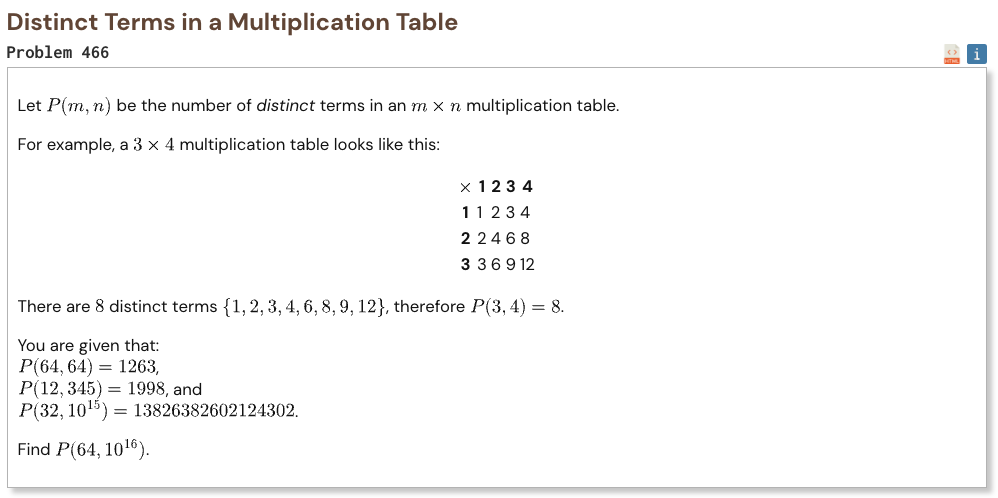

## Initial approach

-   assign every distinct product to the largest row number that divides it
-   for a fixed row, check which larger rows could produce the same product
-   each larger row creates a divisibility condition on the column number
-   reduce these conditions by removing duplicates and any divisor that is already covered by a smaller one
-   use inclusion exclusion to count column numbers that avoid all forbidden divisors
-   combine equal least common multiples while building the inclusion exclusion terms so the number of states stays manageable
-   repeat this for all 64 rows and add their contributions
-   use gcd from the math library to build least common multiples efficiently

In [1]:
%%time

from math import gcd

M = 64
N = 10**16

def count_row(row):
    forbidden = []

    for larger_row in range(row + 1, M + 1):
        value = larger_row // gcd(larger_row, row)

        if value <= N:
            forbidden.append(value)

    forbidden = sorted(set(forbidden))

    minimal = []

    for value in forbidden:
        if all(value % previous != 0 for previous in minimal):
            minimal.append(value)

    coefficients = {1: 1}

    for value in minimal:
        updates = {}

        for current_lcm, coefficient in coefficients.items():
            new_lcm = (
                current_lcm
                // gcd(current_lcm, value)
                * value
            )

            if new_lcm <= N:
                updates[new_lcm] = (
                    updates.get(new_lcm, 0)
                    - coefficient
                )

        for current_lcm, coefficient in updates.items():
            coefficients[current_lcm] = (
                coefficients.get(current_lcm, 0)
                + coefficient
            )

            if coefficients[current_lcm] == 0:
                del coefficients[current_lcm]

    total = 0

    for current_lcm, coefficient in coefficients.items():
        total += coefficient * (N // current_lcm)

    return total

result = sum(
    count_row(row)
    for row in range(1, M + 1)
)

print("Result:", result)

Result: 258381958195474745
CPU times: user 2.75 s, sys: 66 ms, total: 2.82 s
Wall time: 2.82 s
